#**Practical Assignment 1.1:  Implementation of Intelligent Agent : Simple Reflex Agent**

**Name:** Arya M. Bhat

**PRN:** 202401040044

**Roll No:** 10

**Division:** A

**Batch:** A1

###**1. Title**

Smart Vacuum Cleaner for a Modern Office using a Simple Reflex Agent

###**2. Aim**

To design and implement a Smart Vacuum Cleaner using a Simple Reflex Agent that automatically detects the current condition of an office environment and performs appropriate cleaning, movement, obstacle avoidance, edge detection, and battery management actions.

###**3. Objectives**

1. To understand the working principle of a Simple Reflex Agent and its condition-action behavior.
2. To model a modern office environment consisting of multiple rooms with different dirt levels and floor types.
3. To implement condition-based cleaning using different suction modes such as Eco, Normal, and Strong.
4. To enable the vacuum cleaner to detect and avoid obstacles present in the office environment.
5. To implement edge detection and edge-cleaning functionality.
6. To detect situations where the vacuum becomes stuck and automatically recover using reverse and turning movements.
7. To implement battery monitoring and automatic return to the charging station when the battery becomes low.
8. To evaluate the performance of the vacuum cleaner using parameters such as dirt removed, cleaning operations, movements, obstacles avoided, battery usage, and performance score.







###**4. Outcomes**

After completing this practical, the student will be able to:

1. Understand how a Simple Reflex Agent observes the current state of an environment and selects an appropriate action.
2. Represent a real-world office environment using Python data structures.
3. Implement condition-based decision-making for an autonomous cleaning agent.
4. Understand how sensor information such as dirt level, floor type, obstacles, edges, and battery level affects the agent's actions.
5. Implement basic autonomous navigation and recovery mechanisms.
6. Measure the performance of an intelligent agent using suitable performance parameters.

### **5. Conceptual Details**

#### **Simple Reflex Agent**

A Simple Reflex Agent is an intelligent agent that selects an action based on the current condition of its environment. It uses predefined condition-action rules to decide what action should be performed. The agent observes the current state through sensors and immediately performs the appropriate action.

In this practical, a Simple Reflex Agent is used to control a smart vacuum cleaner operating in a modern office environment.

#### **Office Environment**

The office environment consists of two rooms:

- **Room A**
- **Room B**

Each room has the following properties:

- Dirt level
- Floor type
- Obstacle status
- Edge condition

The dirt level of each room is entered by the user, while the floor type and obstacle condition are generated randomly.

#### **Working of the Vacuum Agent**

The vacuum continuously observes its current environment and makes decisions according to the detected conditions.

The main decision rules are:

| Condition | Action |
|---|---|
| Room has more dirt | Select the room for cleaning |
| Dirt > 50% | Use STRONG suction |
| Dirt 21–50% | Use NORMAL suction |
| Dirt ≤ 20% | Use ECO suction |
| Carpet detected | Adjust suction power |
| Obstacle detected | Stop, reverse and turn |
| Edge detected | Activate edge cleaning |
| Vacuum gets stuck | Reverse and turn |
| Battery ≤ 20% | Return to charging station |
| Both rooms are clean | Stop cleaning |

#### **Suction Control**

The vacuum uses three suction modes according to the dirt level:

- **STRONG:** Used when the dirt level is greater than 50%.
- **NORMAL:** Used when the dirt level is between 21% and 50%.
- **ECO:** Used when the dirt level is 20% or below.

The floor type is also considered. When the vacuum is cleaning a carpet, the suction power may be increased depending on the dirt level and available battery.

#### **Obstacle and Edge Handling**

The office may contain obstacles such as tables, chairs, bags, or other objects. When an obstacle is detected, the vacuum stops, reverses, and turns either left or right to avoid it.

The vacuum also checks for edges. When an edge is detected, edge-cleaning mode is activated and the cleaning power is limited.

If the vacuum becomes stuck, it reverses and changes its direction to recover.

#### **Battery Management**

The vacuum starts with a battery level of 100%. Different operations consume different amounts of battery.

The battery level is continuously monitored. When the battery reaches 20% or below, the vacuum returns to the charging station located in Room A. It then recharges until the battery reaches 100% and continues cleaning.

#### **Room Selection**

The vacuum compares the dirt levels of Room A and Room B and selects the room having the higher dirt level.

For example:

**Room A = 70% dirt**

**Room B = 30% dirt**

The vacuum selects **Room A** because it requires more cleaning.

If both rooms have the same dirt level, the vacuum continues from its current location.

#### **Performance Measurement**

The performance of the vacuum cleaner is measured using:

- Total number of steps
- Number of cleaning operations
- Total dirt removed
- Number of room movements
- Number of obstacles avoided
- Number of stuck events
- Number of edge-cleaning operations
- Total battery used
- Final battery level
- Performance score

The performance score increases when dirt is successfully removed and obstacles are avoided. It decreases when the vacuum performs unnecessary movements or encounters a stuck condition.

#### **Overall Working**

The overall working of the Smart Vacuum Cleaner can be represented as:

**Sense Environment → Select Action → Perform Action → Update Environment → Repeat**

The process continues until the dirt level of both rooms becomes zero. Therefore, the vacuum demonstrates how a Simple Reflex Agent can perform autonomous cleaning by responding to the current conditions of a modern office environment.

###**6. Algorithm**

Step 1: Start the program.

Step 2: Create the office environment with two locations, A and B.

Step 3: Enter the dirt level of Room A and Room B.

Step 4: Randomly assign a floor type to each room.

Step 5: Randomly generate obstacles in the rooms.

Step 6: Initialize the vacuum battery to 100% and set Room A as the charging station.

Step 7: Compare the dirt levels of both rooms and select the dirtier room.

Step 8: Check the current battery level.

Step 9: If the battery is 20% or lower, return to the charging station and recharge.

Step 10: Check for obstacles. If an obstacle is detected, stop, reverse, and turn.

Step 11: Check whether the vacuum is stuck. If it is stuck, reverse and turn to recover.

Step 12: Move to the selected room if required.

Step 13: Sense the current dirt level and floor type.

Step 14: Select the appropriate suction mode according to the current condition.

Step 15: Check for an edge and activate edge cleaning if required.

Step 16: Perform the cleaning operation and reduce the dirt level.

Step 17: Update battery usage, cleaning operations, dirt removed, and performance score.

Step 18: Check whether both rooms are clean.

Step 19: If both rooms are not clean, repeat the process.

Step 20: If both rooms are clean, display the final environment and performance report.

Step 21: Stop the program.

###**7. Flowchart**

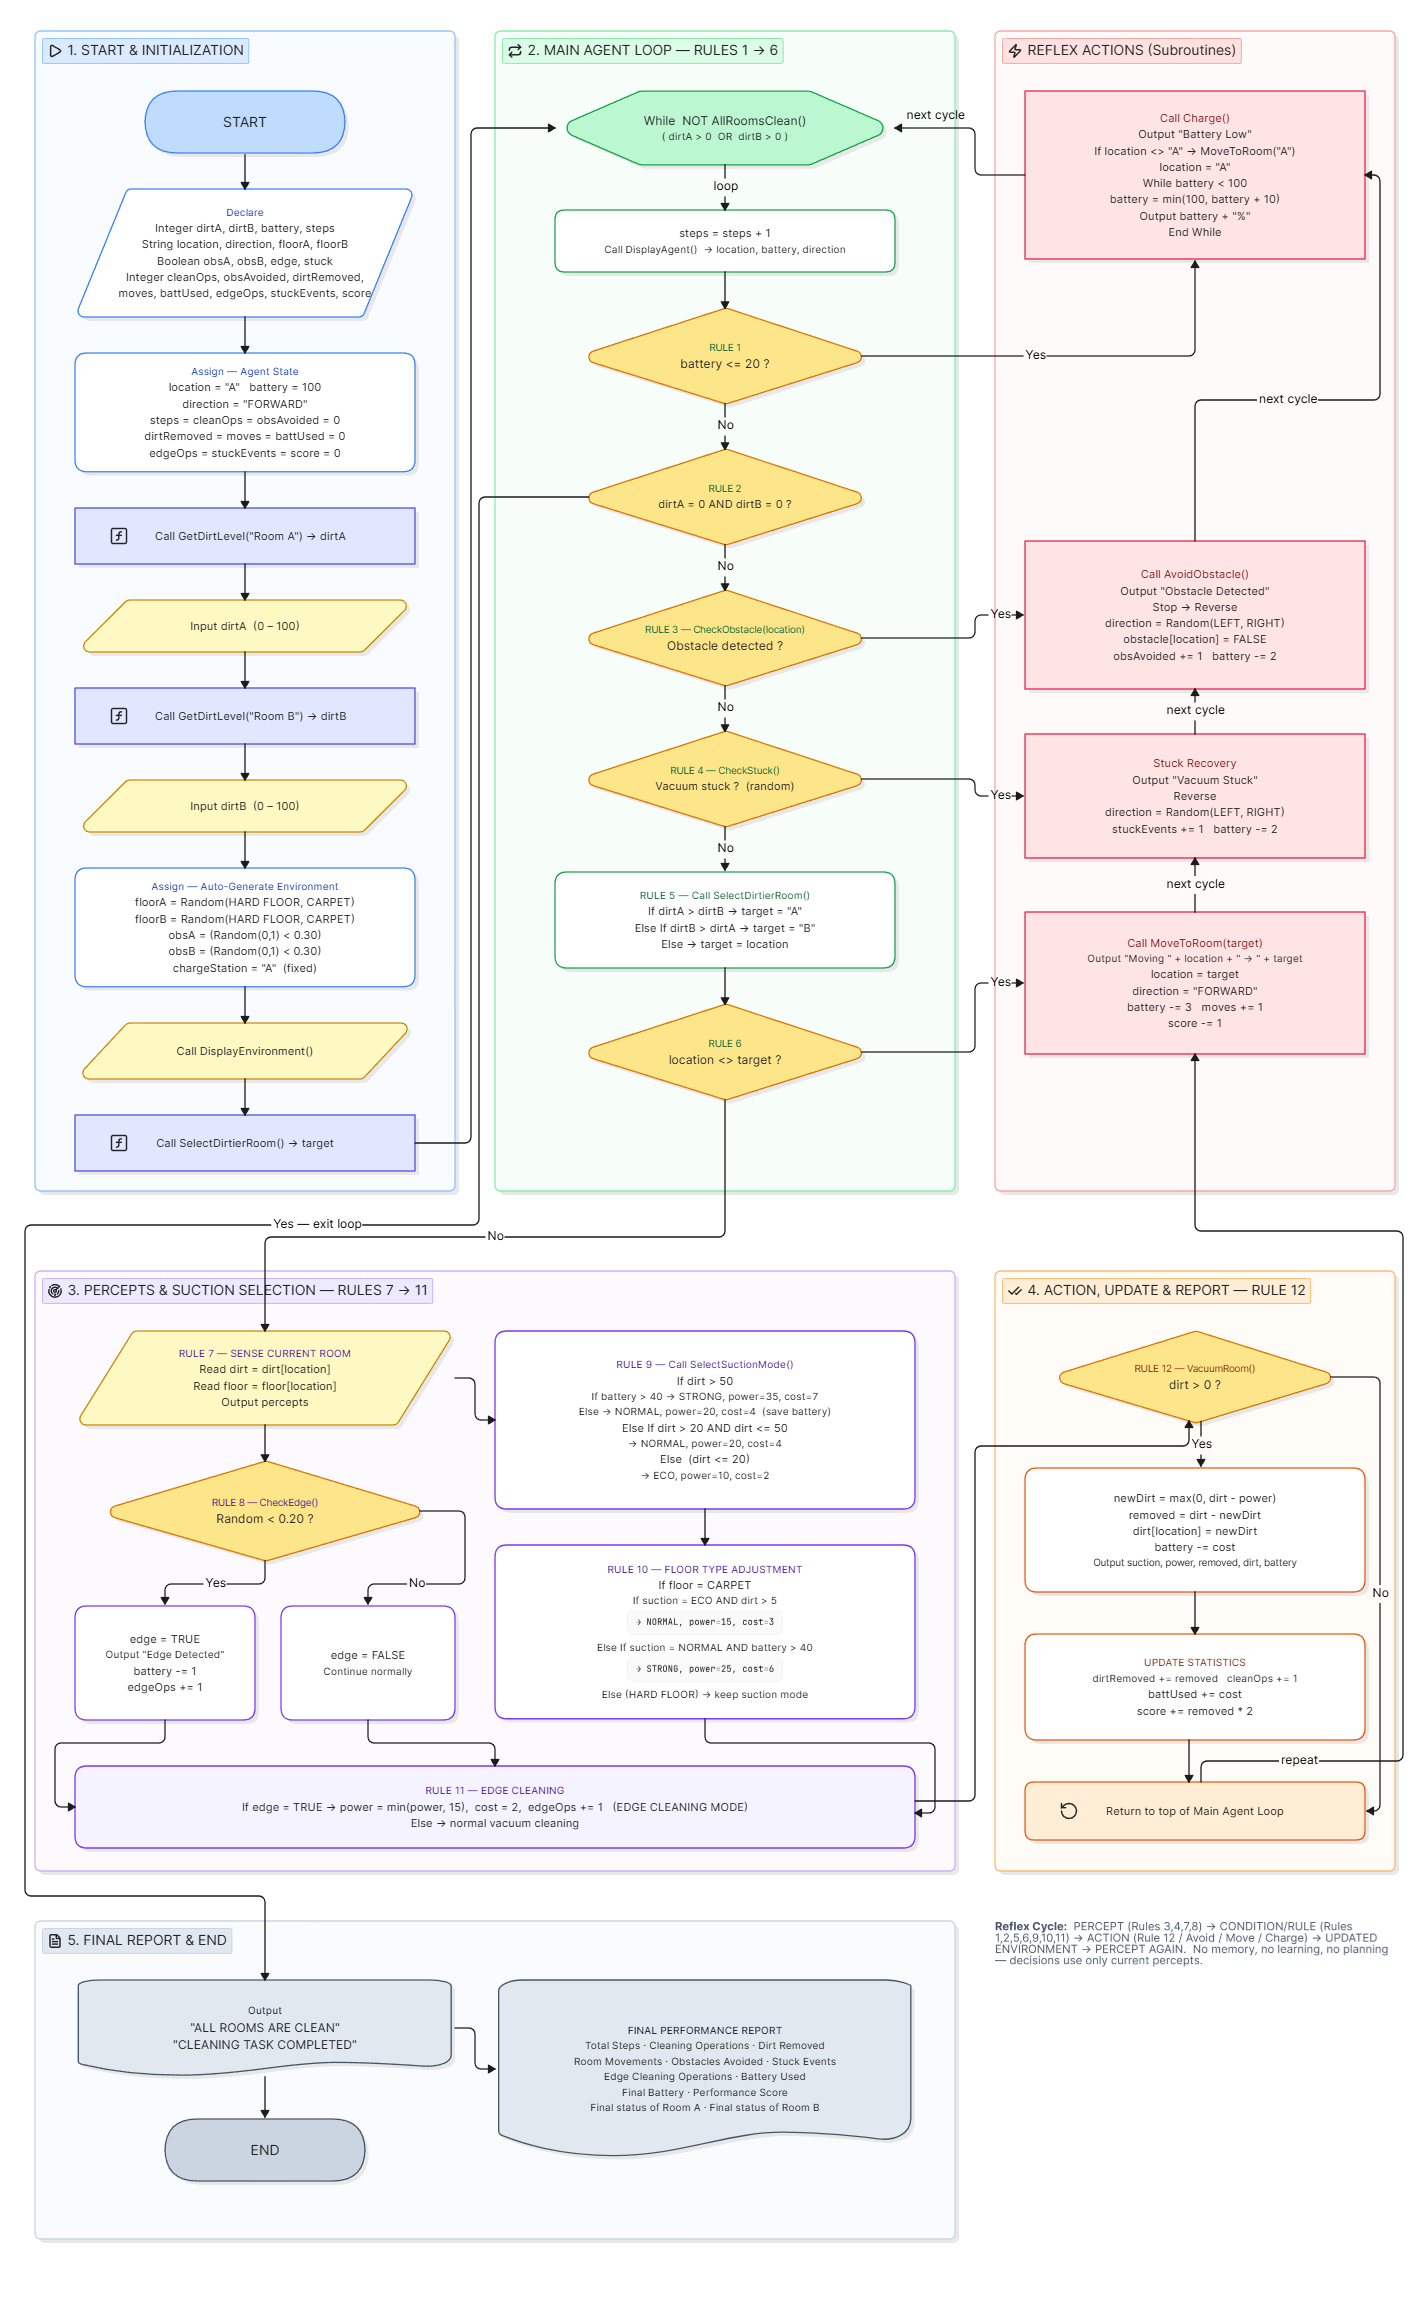

###**8. Program**

In [ ]:
import random
import time

# Office rooms
rooms = {
    "A": {
        "dirt": 0,
        "floor": "",
        "obstacle": False,
        "edge": False
    },
    "B": {
        "dirt": 0,
        "floor": "",
        "obstacle": False,
        "edge": False
    }
}

location = "A"
charging_station = "A"
battery = 100
direction = "FORWARD"

steps = 0
cleaning_operations = 0
obstacles_avoided = 0
dirt_removed = 0
movement_count = 0
battery_used = 0
edge_cleaning_operations = 0
stuck_events = 0
performance_score = 0


# Takes the dirt level as input
def get_dirt_level(room):
    while True:
        try:
            dirt = int(input(f"Enter dirt level for Room {room} (0-100): "))

            if 0 <= dirt <= 100:
                return dirt

            print("Enter a value between 0 and 100.")

        except ValueError:
            print("Enter a valid number.")


# Displays the current office environment
def display_environment():
    print("\n" + "=" * 65)
    print("                    ENVIRONMENT")
    print("=" * 65)

    for room in rooms:
        if rooms[room]["dirt"] == 0:
            status = "CLEAN"
        else:
            status = "DIRTY"

        obstacle = "YES" if rooms[room]["obstacle"] else "NO"
        edge = "YES" if rooms[room]["edge"] else "NO"

        print(
            f"Room {room} | "
            f"Dirt: {rooms[room]['dirt']:>3}% | "
            f"Floor: {rooms[room]['floor']:<10} | "
            f"Obstacle: {obstacle:<3} | "
            f"Edge: {edge:<3} | "
            f"{status}"
        )

    print("=" * 65)


# Selects the room having more dirt
def select_dirtier_room():
    dirt_a = rooms["A"]["dirt"]
    dirt_b = rooms["B"]["dirt"]

    if dirt_a > dirt_b:
        selected_room = "A"

    elif dirt_b > dirt_a:
        selected_room = "B"

    else:
        selected_room = location

    print(
        f"Room A: {dirt_a}% dirt | "
        f"Room B: {dirt_b}% dirt"
    )

    print(f"Decision → Select Room {selected_room}")

    return selected_room


# Selects suction mode based on dirt and floor
def select_suction_mode(dirt, floor):
    if dirt > 50:

        if battery > 40:
            mode = "STRONG"
            cleaning_power = 35
            battery_cost = 7

        else:
            mode = "NORMAL"
            cleaning_power = 20
            battery_cost = 4

    elif dirt > 20:

        mode = "NORMAL"
        cleaning_power = 20
        battery_cost = 4

    else:

        mode = "ECO"
        cleaning_power = 10
        battery_cost = 2

    if floor == "CARPET":

        if mode == "ECO" and dirt > 5:
            mode = "NORMAL"
            cleaning_power = 15
            battery_cost = 3

        elif mode == "NORMAL" and battery > 40:
            mode = "STRONG"
            cleaning_power = 25
            battery_cost = 6

    return mode, cleaning_power, battery_cost


# Checks whether an obstacle is present
def check_obstacle():
    if rooms[location]["obstacle"]:
        print("Obstacle detected!")
        return True

    return False


# Avoids the obstacle by reversing and turning
def avoid_obstacle():
    global battery
    global battery_used
    global obstacles_avoided
    global direction
    global performance_score

    print("Decision → STOP → REVERSE → TURN")

    direction = "REVERSE"

    battery -= 1
    battery_used += 1

    direction = random.choice(["LEFT", "RIGHT"])

    battery -= 1
    battery_used += 1

    rooms[location]["obstacle"] = False

    obstacles_avoided += 1
    performance_score += 2

    print(f"New direction → {direction}")
    print("Obstacle avoided.")


# Checks for an edge in the current room
def check_edge():
    global battery
    global battery_used

    edge_detected = random.random() < 0.20

    if edge_detected:

        rooms[location]["edge"] = True

        battery -= 1
        battery_used += 1

        print("Edge detected → Edge cleaning activated.")

        return True

    else:

        rooms[location]["edge"] = False

        return False


# Checks whether the vacuum is stuck
def check_stuck():
    global stuck_events
    global battery
    global battery_used
    global direction
    global performance_score

    stuck = random.random() < 0.10

    if stuck:

        print("Vacuum stuck → Reversing and turning.")

        direction = "REVERSE"

        battery -= 2
        battery_used += 2

        direction = random.choice(["LEFT", "RIGHT"])

        stuck_events += 1
        performance_score -= 2

        print(f"Recovered → Direction: {direction}")

        return True

    return False


# Cleans the current room
def vacuum_room():
    global battery
    global cleaning_operations
    global dirt_removed
    global battery_used
    global performance_score
    global edge_cleaning_operations

    current_dirt = rooms[location]["dirt"]
    floor = rooms[location]["floor"]

    mode, cleaning_power, battery_cost = select_suction_mode(
        current_dirt,
        floor
    )

    if rooms[location]["edge"]:

        cleaning_power = min(cleaning_power, 15)
        battery_cost = 2
        edge_cleaning_operations += 1

        action = "EDGE CLEANING"

    else:

        action = "NORMAL VACUUMING"

    old_dirt = rooms[location]["dirt"]

    rooms[location]["dirt"] = max(
        0,
        old_dirt - cleaning_power
    )

    removed = old_dirt - rooms[location]["dirt"]

    battery -= battery_cost
    battery_used += battery_cost

    dirt_removed += removed
    cleaning_operations += 1

    performance_score += removed * 2

    print(f"Action → {action}")
    print(
        f"Suction: {mode} | "
        f"Removed: {removed}% | "
        f"Remaining: {rooms[location]['dirt']}% | "
        f"Battery: {battery}%"
    )


# Moves the vacuum to another room
def move_to_room(target_room):
    global location
    global battery
    global movement_count
    global battery_used
    global performance_score
    global direction

    if location == target_room:
        return

    print(f"Decision → Move from Room {location} to Room {target_room}")

    direction = "FORWARD"
    location = target_room

    battery -= 3
    battery_used += 3

    movement_count += 1
    performance_score -= 1

    print(f"Arrived at Room {location} | Battery: {battery}%")


# Returns the vacuum to the charging station
def charge():
    global battery
    global location
    global direction

    print("\nBATTERY LOW")
    print(f"Current battery: {battery}%")

    if location != charging_station:

        print("Returning to charging station...")

        direction = "FORWARD"
        location = charging_station

        print("Reached Room A.")

    print("Charging...")

    while battery < 100:

        battery += 10

        if battery > 100:
            battery = 100

        print(f"Battery: {battery}%")
        time.sleep(0.1)

    print("Battery fully charged.")


# Checks whether both rooms are clean
def all_rooms_clean():
    return (
        rooms["A"]["dirt"] == 0
        and
        rooms["B"]["dirt"] == 0
    )


# Main routine of the simple reflex agent
def simple_reflex_agent():
    global steps

    while True:

        steps += 1

        print("\n" + "=" * 65)
        print(f"STEP {steps}")
        print("=" * 65)

        print(
            f"Location: Room {location} | "
            f"Battery: {battery}% | "
            f"Direction: {direction}"
        )

        if battery <= 20:
            charge()
            continue

        if all_rooms_clean():
            print("\nALL ROOMS ARE CLEAN!")
            break

        if check_obstacle():
            avoid_obstacle()
            continue

        if check_stuck():
            continue

        target_room = select_dirtier_room()

        if location != target_room:
            move_to_room(target_room)
            continue

        current_dirt = rooms[location]["dirt"]
        current_floor = rooms[location]["floor"]

        print("\nSENSORS")
        print(
            f"Dirt: {current_dirt}% | "
            f"Floor: {current_floor}"
        )

        check_edge()

        if current_dirt > 0:

            print(
                f"Decision → Room {location} is dirty. "
                f"Cleaning..."
            )

            vacuum_room()

        else:
            print("Room is already clean.")


# Start of the vacuum cleaner program
print("\n" + "=" * 65)
print("              SMART VACUUM CLEANER")
print("           SIMPLE REFLEX AGENT")
print("=" * 65)

print("\nINITIAL SETUP")

rooms["A"]["dirt"] = get_dirt_level("A")
rooms["B"]["dirt"] = get_dirt_level("B")

# Assigns a random floor type to each room
rooms["A"]["floor"] = random.choice(
    ["HARD FLOOR", "CARPET"]
)

rooms["B"]["floor"] = random.choice(
    ["HARD FLOOR", "CARPET"]
)

# Randomly places obstacles in the rooms
rooms["A"]["obstacle"] = random.random() < 0.30
rooms["B"]["obstacle"] = random.random() < 0.30

battery = 100

print("\nINITIAL ENVIRONMENT")
display_environment()

print("Charging Station: Room A")
print("Initial Battery: 100%")

print("\nSTARTING DECISION")

location = select_dirtier_room()

print(f"Vacuum starts in Room {location}.")

time.sleep(1)

# Runs the vacuum cleaning process
simple_reflex_agent()

# Displays the final performance report
print("\n" + "=" * 65)
print("                     FINAL REPORT")
print("=" * 65)

print("\nCleaning completed successfully!\n")

print("PERFORMANCE")
print("-" * 40)

print(f"Total Steps          : {steps}")
print(f"Cleaning Operations  : {cleaning_operations}")
print(f"Dirt Removed         : {dirt_removed}%")
print(f"Room Movements       : {movement_count}")
print(f"Obstacles Avoided    : {obstacles_avoided}")
print(f"Stuck Events         : {stuck_events}")
print(f"Edge Cleaning        : {edge_cleaning_operations}")
print(f"Battery Used         : {battery_used}%")
print(f"Final Battery        : {battery}%")
print(f"Performance Score    : {performance_score}")

print("\nFINAL ENVIRONMENT")
display_environment()

print("\n" + "=" * 65)
print("             VACUUM CLEANING COMPLETED")
print("=" * 65)


              SMART VACUUM CLEANER
           SIMPLE REFLEX AGENT

INITIAL SETUP
Enter dirt level for Room A (0-100): 50
Enter dirt level for Room B (0-100): 20

INITIAL ENVIRONMENT

                    ENVIRONMENT
Room A | Dirt:  50% | Floor: HARD FLOOR | Obstacle: YES | Edge: NO  | DIRTY
Room B | Dirt:  20% | Floor: HARD FLOOR | Obstacle: NO  | Edge: NO  | DIRTY
Charging Station: Room A
Initial Battery: 100%

STARTING DECISION
Room A: 50% dirt | Room B: 20% dirt
Decision → Select Room A
Vacuum starts in Room A.

STEP 1
Location: Room A | Battery: 100% | Direction: FORWARD
Obstacle detected!
Decision → STOP → REVERSE → TURN
New direction → LEFT
Obstacle avoided.

STEP 2
Location: Room A | Battery: 98% | Direction: LEFT
Room A: 50% dirt | Room B: 20% dirt
Decision → Select Room A

SENSORS
Dirt: 50% | Floor: HARD FLOOR
Decision → Room A is dirty. Cleaning...
Action → NORMAL VACUUMING
Suction: NORMAL | Removed: 20% | Remaining: 30% | Battery: 94%

STEP 3
Location: Room A | Battery: 94% 

###**9. Conclusion**
The Smart Vacuum Cleaner successfully demonstrates the working of a Simple Reflex Agent in a modern office environment. The agent observes the current conditions such as dirt level, floor type, obstacles, edges, stuck situations, and battery level and selects an appropriate action using condition-action rules. Different suction modes allow the vacuum to adapt its cleaning according to the current dirt level and floor condition. Obstacle avoidance, edge detection, stuck recovery, and automatic battery charging make the simulation more realistic. The performance measures help evaluate the efficiency of the agent. Thus, the practical demonstrates how a Simple Reflex Agent can be used to perform autonomous cleaning in a modern office environment.


###**10. Github Repository Link**

https://github.com/aryabhat2810/AIML-Lab.git